# Handwritten Character Recognition (CNN, EMNIST Balanced)

CodeAlpha Machine Learning internship, Task 3.

A convolutional neural network that reads handwritten digits and letters (47 classes: 10 digits plus 37 letter classes, where look-alike upper/lower-case pairs such as C/c are merged). Includes an error analysis and a simple context trick (restricting the answer to digits or to letters).

Data: Kaggle dataset *EMNIST (Extended MNIST)* by Chris Crawford, `emnist-balanced-*.csv`. Attach it to the notebook as an input before running.

## 1. Load the EMNIST Balanced data

Train: (112800, 28, 28) Test: (18800, 28, 28) Classes: 47


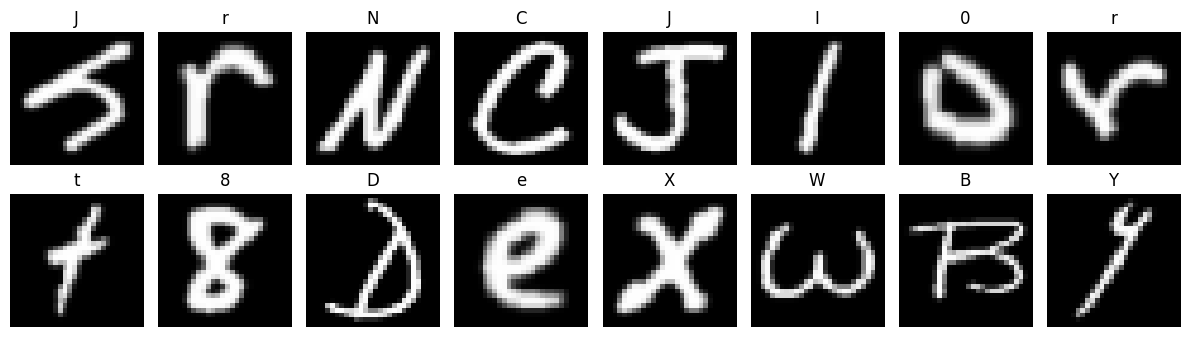

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DIR = "/kaggle/input/datasets/crawford/emnist/"
train = pd.read_csv(DIR + "emnist-balanced-train.csv", header=None)
test = pd.read_csv(DIR + "emnist-balanced-test.csv", header=None)

# label -> character (ASCII code in the mapping file)
mapping = {int(a): chr(int(b)) for a, b in (line.split() for line in open(DIR + "emnist-balanced-mapping.txt"))}

def to_images(df):
    y = df[0].values
    # EMNIST images are stored transposed, so swap the two image axes
    X = df.drop(columns=0).values.reshape(-1, 28, 28).transpose(0, 2, 1).astype("float32") / 255.0
    return X, y

X_train_full, y_train_full = to_images(train)
X_test, y_test = to_images(test)
print("Train:", X_train_full.shape, "Test:", X_test.shape, "Classes:", len(mapping))

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.ravel(), np.random.RandomState(0).choice(len(X_train_full), 16, replace=False)):
    ax.imshow(X_train_full[i], cmap="gray"); ax.set_title(mapping[y_train_full[i]]); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Validation split and CNN architecture

In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

# keep 10% of the training images as a validation set (stratified), the test set stays untouched
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full)

# a CNN expects a channel axis: (N, 28, 28) -> (N, 28, 28, 1)
X_train, X_val, X_test_c = X_train[..., None], X_val[..., None], X_test[..., None]

tf.random.set_seed(42)
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(47, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test_c.shape)
model.summary()

I0000 00:00:1795469689.125335      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795469707.566745      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | GPUs: []
Train: (101520, 28, 28, 1) Val: (11280, 28, 28, 1) Test: (18800, 28, 28, 1)


E0000 00:00:1795469712.040090      49 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 47)             │         6,063 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 229,807 (897.68 KB)

 Trainable params: 229,807 (897.68 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Train with early stopping

In [4]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=8, batch_size=128,
    callbacks=[early_stop], verbose=2,
)

Epoch 1/8
794/794 - 47s - 59ms/step - accuracy: 0.6458 - loss: 1.1890 - val_accuracy: 0.8248 - val_loss: 0.5220
Epoch 2/8
794/794 - 45s - 56ms/step - accuracy: 0.7900 - loss: 0.6445 - val_accuracy: 0.8466 - val_loss: 0.4452
Epoch 3/8
794/794 - 45s - 56ms/step - accuracy: 0.8171 - loss: 0.5541 - val_accuracy: 0.8574 - val_loss: 0.4112
Epoch 4/8
794/794 - 45s - 57ms/step - accuracy: 0.8304 - loss: 0.5033 - val_accuracy: 0.8623 - val_loss: 0.3914
Epoch 5/8
794/794 - 48s - 61ms/step - accuracy: 0.8415 - loss: 0.4670 - val_accuracy: 0.8690 - val_loss: 0.3754
Epoch 6/8
794/794 - 47s - 59ms/step - accuracy: 0.8485 - loss: 0.4410 - val_accuracy: 0.8704 - val_loss: 0.3681
Epoch 7/8
794/794 - 44s - 55ms/step - accuracy: 0.8551 - loss: 0.4179 - val_accuracy: 0.8732 - val_loss: 0.3617
Epoch 8/8
794/794 - 44s - 55ms/step - accuracy: 0.8583 - loss: 0.3992 - val_accuracy: 0.8757 - val_loss: 0.3563


## 4. Evaluate on the untouched test set

Test accuracy: 0.8719 | Test loss: 0.3728
Macro avg  precision: 0.874  recall: 0.872  f1: 0.870

Hardest characters (F1):
L    0.48
q    0.59
F    0.60
1    0.62
g    0.65
f    0.66
I    0.66
O    0.67

Easiest characters (F1):
M    0.97
E    0.97
7    0.97
W    0.98
3    0.98

Most frequent mistakes (true -> predicted):
  F -> f: 183 times
  L -> 1: 169 times
  O -> 0: 129 times
  q -> 9: 109 times
  0 -> O: 94 times
  I -> 1: 88 times
  1 -> I: 79 times
  L -> I: 78 times


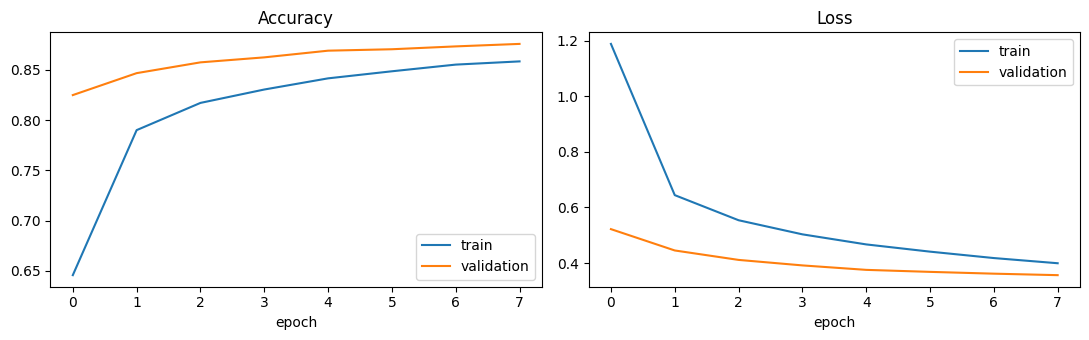

In [5]:
from sklearn.metrics import classification_report, confusion_matrix

test_loss, test_acc = model.evaluate(X_test_c, y_test, batch_size=256, verbose=0)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")

pred = model.predict(X_test_c, batch_size=256, verbose=0).argmax(axis=1)
labels = [mapping[i] for i in range(47)]
rep = classification_report(y_test, pred, target_names=labels, output_dict=True, zero_division=0)
print("Macro avg  precision: %.3f  recall: %.3f  f1: %.3f" % (
    rep["macro avg"]["precision"], rep["macro avg"]["recall"], rep["macro avg"]["f1-score"]))

f1 = pd.Series({c: rep[c]["f1-score"] for c in labels}).sort_values()
print("\nHardest characters (F1):"); print(f1.head(8).round(2).to_string())
print("\nEasiest characters (F1):"); print(f1.tail(5).round(2).to_string())

cm = confusion_matrix(y_test, pred); np.fill_diagonal(cm, 0)
print("\nMost frequent mistakes (true -> predicted):")
for k in np.argsort(cm.ravel())[::-1][:8]:
    i, j = np.unravel_index(k, cm.shape)
    print(f"  {labels[i]} -> {labels[j]}: {cm[i, j]} times")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.history["accuracy"], label="train"); ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train"); ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Use context: restrict the answer to digits or letters

In [6]:
probs = model.predict(X_test_c, verbose=0)
digit_mask = np.array([mapping[i].isdigit() for i in range(47)])
for name, allowed in [("digits", digit_mask), ("letters", ~digit_mask)]:
    sel = allowed[y_test]
    plain = probs[sel].argmax(1)
    masked = np.where(allowed, probs[sel], 0).argmax(1)
    print(name, "| samples:", sel.sum(), "| no mask:", round((plain == y_test[sel]).mean(), 4), "| with mask:", round((masked == y_test[sel]).mean(), 4))

digits | samples: 4000 | no mask: 0.875 | with mask: 0.9915
letters | samples: 14800 | no mask: 0.871 | with mask: 0.9067


## 6. Save the model

In [7]:
import json, os
model.save("emnist_cnn.keras")
json.dump({str(k): v for k, v in mapping.items()}, open("label_mapping.json", "w"))
print(os.listdir("."), "| model size (MB):", round(os.path.getsize("emnist_cnn.keras") / 1e6, 2))

['.virtual_documents', 'emnist_cnn.keras', 'label_mapping.json'] | model size (MB): 2.8
